In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("big5_players_data.csv")
print(f"Жүктелді: {df.shape[0]} жол, {df.shape[1]} баған")

# 90 минуттан аз ойнағандарды сүзу және негізгі бағандарды тексеру
df = df[df["minutes_played"] >= 90].copy()
df = df.dropna(subset=["market_value", "age", "position", "league", "club_tier", "contract_years"]).copy()
df = df[df["market_value"] > 0].copy()

# Нақты логарифм және центрленген жас квадраты (VIF қатесін болдырмау үшін)
df["log_market_value"] = np.log(df["market_value"])
df["age_centered"] = df["age"] - df["age"].mean()
df["age_sq"] = df["age"] ** 2
df["age_centered_sq"] = df["age_centered"] ** 2

# Жалпы регрессияға арналған 0-мен толтырылған позициялық метрикалар
df["tackles_filled"] = df["tackles_per90"].fillna(0.0)
df["prog_passes_filled"] = df["prog_passes_per90"].fillna(0.0)
df["xg_filled"] = df["xg_per90"].fillna(0.0)

# 1.5 * IQR outliers белгілеу
q1, q3 = np.percentile(df["log_market_value"], [25, 75])
iqr = q3 - q1
df["is_outlier"] = (df["log_market_value"] < (q1 - 1.5 * iqr)) | (
    df["log_market_value"] > (q3 + 1.5 * iqr)
)

# Тазаланған файлды сақтау
df.to_csv("cleaned_players_data.csv", index=False)

# Позициялар бойынша статистикалық кесте
summary_df = (
    df.groupby("position")
    .agg(
        player_count=("market_value", "count"),
        mean_mv_eur=("market_value", "mean"),
        median_mv_eur=("market_value", "median"),
        p25_mv_eur=("market_value", lambda x: np.percentile(x, 25)),
        p75_mv_eur=("market_value", lambda x: np.percentile(x, 75)),
        std_mv_eur=("market_value", "std"),
        mean_age=("age", "mean"),
        mean_minutes=("minutes_played", "mean"),
    )
    .reset_index()
)
summary_df.to_csv("metrics_summary.csv", index=False)

print(f"Тазаланған жолдар саны (N): {len(df)} | Outliers: {df['is_outlier'].sum()}")
display(summary_df)

Жүктелді: 1200 жол, 12 баған
Тазаланған жолдар саны (N): 1200 | Outliers: 1


,position,player_count,mean_mv_eur,median_mv_eur,p25_mv_eur,p75_mv_eur,std_mv_eur,mean_age,mean_minutes
0,Defender,431,6.231401e+07,44010544.0,22443014.00,8.126048e+07,5.811000e+07,26.635731,1882.779582
1,Forward,362,1.012945e+08,75402838.0,32539682.25,1.364740e+08,9.316500e+07,26.502762,1940.389503
2,Midfielder,407,8.013252e+07,57334054.0,25915092.00,1.156556e+08,7.448397e+07,26.361179,1976.469287


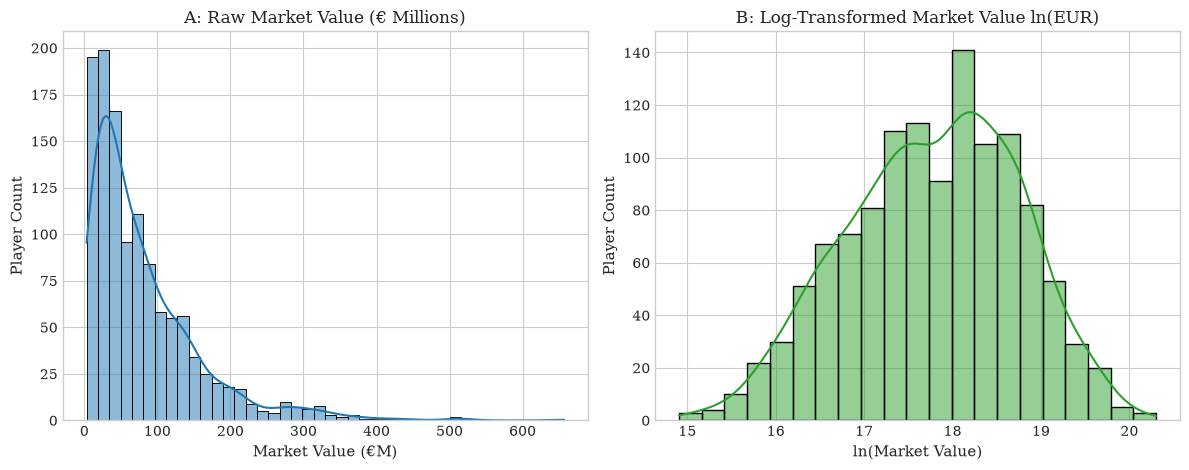

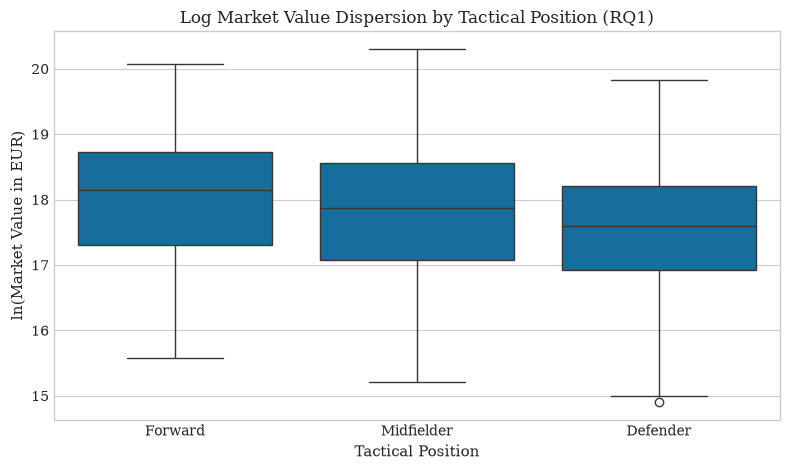

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.labelsize": 11})

# Figure 1: Нарықтық құнның таралуы (Raw vs Log)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.histplot(df["market_value"] / 1e6, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("A: Raw Market Value (€ Millions)")
axes[0].set_xlabel("Market Value (€M)")
axes[0].set_ylabel("Player Count")

sns.histplot(df["log_market_value"], kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title("B: Log-Transformed Market Value ln(EUR)")
axes[1].set_xlabel("ln(Market Value)")
axes[1].set_ylabel("Player Count")
fig.tight_layout()
fig.savefig("fig1_mv_distribution.png", dpi=300, bbox_inches="tight")
fig.savefig("fig1_mv_distribution.pdf", bbox_inches="tight")
plt.show()

# Figure 2: Позициялар бойынша таралу (RQ1)
fig, ax = plt.subplots(figsize=(8, 4.8))
order = ["Forward", "Midfielder", "Defender"]
sns.boxplot(data=df, x="position", y="log_market_value", order=order, ax=ax)
ax.set_title("Log Market Value Dispersion by Tactical Position (RQ1)")
ax.set_xlabel("Tactical Position")
ax.set_ylabel("ln(Market Value in EUR)")
fig.tight_layout()
fig.savefig("fig2_position_boxplot.png", dpi=300, bbox_inches="tight")
fig.savefig("fig2_position_boxplot.pdf", bbox_inches="tight")
plt.show()